# Project Deliverable 3: Classification, Clustering, and Pattern Mining

**Student:** Rohail Shaikh , Phaneendra Vanapamula, Abhilash Marthala  
**Course:** Advanced Big Data and Data Mining (MSCS-634-M50)  
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling

This notebook continues the Bike Sharing project from Deliverables 1 and 2. It predicts
high-demand hours with Decision Tree and k-NN classifiers, tunes the tree, groups similar
hours with K-Means, and finds demand-related association rules with FP-Growth.

## 1. Dataset and project continuity

The same `bike_sharing_cleaned.csv` contains **17,379 hourly records and 17 cleaned columns**
from 2011–2012 in Washington, D.C. (Fanaee-T, 2013). The CSV is included and remains unchanged.
Absent hours are not filled. The 13 calendar features from Deliverable 2 are recreated below.

Classification keeps Deliverable 2's training period through July 2012, test period from
August 2012, and five expanding calendar validation folds. All three rental count columns
are excluded from classifier inputs. Counts define the target and are used after clustering
to describe demand, rather than to form clusters.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, silhouette_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from mlxtend.frequent_patterns import fpgrowth, association_rules

OUTPUT = Path('results')
OUTPUT.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

df = pd.read_csv('bike_sharing_cleaned.csv', parse_dates=['date', 'timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)
assert df.shape == (17379, 17) and not df.isna().any().any()
assert not df['timestamp'].duplicated().any()
assert (df['total_rentals'] == df['casual_rentals'] + df['registered_rentals']).all()

# Fixed calendar formulas from Deliverable 2; no fitted statistics or rental counts.
engineered = []
for harmonic in (1, 2, 3):
    angle = 2 * np.pi * harmonic * df['hour'] / 24
    for label, values in [('sin', np.sin(angle)), ('cos', np.cos(angle))]:
        name = f'hour_{label}_{harmonic}'
        df[name] = values
        df[f'work_{name}'] = values * df['working_day']
        engineered.extend([name, f'work_{name}'])
df['days_since_start'] = (df['timestamp'] - pd.Timestamp('2011-01-01')).dt.total_seconds() / 86400
engineered.append('days_since_start')

numeric = ['hour', 'year', 'working_day', 'holiday', 'temperature_norm',
           'feels_like_norm', 'humidity_norm', 'windspeed_norm'] + engineered
categorical = ['month', 'season', 'weather']
predictors = numeric + categorical
assert not {'total_rentals', 'casual_rentals', 'registered_rentals'} & set(predictors)
print(f'Records: {len(df):,}; classifier inputs: {len(predictors)}')
display(df[['timestamp', 'hour', 'working_day', 'temperature_norm', 'total_rentals']].head())

Records: 17,379; classifier inputs: 24


,timestamp,hour,working_day,temperature_norm,total_rentals
0,2011-01-01 00:00:00,0,0,0.2400,16
1,2011-01-01 01:00:00,1,0,0.2200,40
2,2011-01-01 02:00:00,2,0,0.2200,32
3,2011-01-01 03:00:00,3,0,0.2400,13
4,2011-01-01 04:00:00,4,0,0.2400,1


## 2. High-demand target and time-based validation

**High demand** means rentals at or above the **75th percentile of the initial training
window, January–September 2011**. This threshold is fixed before every validation and test
period. It represents high demand relative to that earlier baseline, not the top quarter
of each later period. Normal demand is labeled 0 and high demand 1.

Using the first training window prevents later rental counts from setting the label threshold.
Every validation fold then trains on earlier dates and validates on the next two calendar
months. Fitted preprocessing stays inside each fold.

In [2]:
initial_end = pd.Timestamp('2011-10-01')
cutoff = pd.Timestamp('2012-08-01')
threshold = df.loc[df['timestamp'] < initial_end, 'total_rentals'].quantile(0.75)
df['high_demand'] = (df['total_rentals'] >= threshold).astype(int)

train_mask = df['timestamp'] < cutoff
train = df.loc[train_mask].copy()
test = df.loc[~train_mask].copy()
X_train, X_test = train[predictors], test[predictors]
y_train, y_test = train['high_demand'], test['high_demand']
times = train['timestamp'].reset_index(drop=True)

cv_splits, fold_rows = [], []
for fold, start in enumerate(pd.to_datetime([
    '2011-10-01', '2011-12-01', '2012-02-01', '2012-04-01', '2012-06-01'
]), start=1):
    end = start + pd.DateOffset(months=2)
    train_idx = np.flatnonzero(times < start)
    valid_idx = np.flatnonzero((times >= start) & (times < end))
    assert times.iloc[train_idx].max() < times.iloc[valid_idx].min()
    assert y_train.iloc[train_idx].nunique() == y_train.iloc[valid_idx].nunique() == 2
    cv_splits.append((train_idx, valid_idx))
    fold_rows.append({'Fold': fold, 'Train through': str(times.iloc[train_idx].max().date()),
                      'Validation start': str(start.date()),
                      'Validation end': str((end - pd.Timedelta(days=1)).date()),
                      'Train rows': len(train_idx), 'Validation rows': len(valid_idx)})

assert train['timestamp'].max() < test['timestamp'].min()
print(f'Fixed high-demand threshold: {threshold:.0f} rentals/hour')
display(pd.DataFrame({
    'Period': ['Training', 'Test'], 'Rows': [len(train), len(test)],
    'Normal': [(y_train == 0).sum(), (y_test == 0).sum()],
    'High': [y_train.sum(), y_test.sum()],
    'High demand (%)': [100 * y_train.mean(), 100 * y_test.mean()]
}))
display(pd.DataFrame(fold_rows))

Fixed high-demand threshold: 213 rentals/hour


,Period,Rows,Normal,High,High demand (%)
0,Training,13747,9339,4408,32.0652
1,Test,3632,1853,1779,48.9813


,Fold,Train through,Validation start,Validation end,Train rows,Validation rows
0,1,2011-09-30,2011-10-01,2011-11-30,6442,1462
1,2,2011-11-30,2011-12-01,2012-01-31,7904,1482
2,3,2012-01-31,2012-02-01,2012-03-31,9386,1435
3,4,2012-03-31,2012-04-01,2012-05-31,10821,1462
4,5,2012-05-31,2012-06-01,2012-07-31,12283,1464


## 3. Classification models and hyperparameter tuning

- **Decision Tree baseline:** Uses the default tree settings and can learn nonlinear splits.
- **k-NN:** Uses 15 Euclidean-distance neighbors with closer neighbors receiving more weight.
  Fifteen neighbors provide a fixed, moderately smoothed comparison.
- **Tuned Decision Tree:** Uses grid search to select settings on the training folds.

Numeric inputs are standardized for k-NN; the shared pipeline also scales tree inputs,
which preserves their ordering. Category codes are one-hot encoded using their known domains.

| Tree parameter | Values compared | Reason |
|---|---|---|
| `max_depth` | 4, 6, 8, None | Compare simpler trees with an unrestricted tree. |
| `min_samples_leaf` | 1, 10, 30 | Test whether larger leaves reduce noisy splits. |
| `class_weight` | None, balanced | Check whether weighting helps identify high-demand hours. |

The **24 combinations** are evaluated on five folds. Selection uses **F1 for high demand**,
which balances precision and recall. Precision measures how often a high-demand warning is
correct; recall measures how many actual high-demand hours are detected. Accuracy measures
overall correctness, and ROC-AUC measures probability ranking across thresholds. The model
with the best mean CV F1 is recommended before test evaluation. CV scores guide selection
and are not independent estimates after tuning (Wu, 2024, Chapter 6).

In [3]:
def classification_pipeline(classifier):
    preprocessing = ColumnTransformer([
        ('numeric', StandardScaler(), numeric),
        ('category', OneHotEncoder(
            categories=[list(range(1, 13)), [1, 2, 3, 4], [1, 2, 3, 4]],
            drop='first', handle_unknown='ignore', sparse_output=False
        ), categorical)
    ])
    return Pipeline([('preprocess', preprocessing), ('classifier', classifier)])

tree_grid = {'classifier__max_depth': [4, 6, 8, None],
             'classifier__min_samples_leaf': [1, 10, 30],
             'classifier__class_weight': [None, 'balanced']}
specs = {
    'Decision Tree baseline': (DecisionTreeClassifier(random_state=42), {}),
    'k-NN': (KNeighborsClassifier(n_neighbors=15, weights='distance', metric='euclidean'), {}),
    'Decision Tree tuned': (DecisionTreeClassifier(random_state=42), tree_grid)
}
searches, cv_rows = {}, []
for name, (classifier, grid) in specs.items():
    search = GridSearchCV(classification_pipeline(classifier), grid, cv=cv_splits,
                          scoring={'f1': 'f1', 'auc': 'roc_auc', 'accuracy': 'accuracy'},
                          refit='f1', n_jobs=1, error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    i = search.best_index_
    cv_rows.append({'Model': name, 'CV F1': search.cv_results_['mean_test_f1'][i],
                    'CV F1 SD': search.cv_results_['std_test_f1'][i],
                    'CV ROC-AUC': search.cv_results_['mean_test_auc'][i]})

cv_results = pd.DataFrame(cv_rows).set_index('Model')
recommended_name = cv_results['CV F1'].idxmax()
best_parameters = searches['Decision Tree tuned'].best_params_
display(cv_results.round(4))
print('Selected tree parameters:', best_parameters)
print('Recommended using CV F1:', recommended_name)

# Show the top candidates so the selected settings can be reviewed.
tuning_table = pd.DataFrame(searches['Decision Tree tuned'].cv_results_)
display(tuning_table[['param_classifier__max_depth', 'param_classifier__min_samples_leaf',
                      'param_classifier__class_weight', 'mean_test_f1', 'std_test_f1']]
        .sort_values('mean_test_f1', ascending=False).head().reset_index(drop=True))

,CV F1,CV F1 SD,CV ROC-AUC
Model,,,
Decision Tree baseline,0.7705,0.1155,0.8431
k-NN,0.8220,0.0690,0.9498
Decision Tree tuned,0.8256,0.0812,0.9381


Selected tree parameters: {'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__min_samples_leaf': 10}
Recommended using CV F1: Decision Tree tuned


,param_classifier__max_depth,param_classifier__min_samples_leaf,param_classifier__class_weight,mean_test_f1,std_test_f1
0,None,10,NaN,0.8256,0.0812
1,8,30,NaN,0.8220,0.0769
2,8,10,NaN,0.8209,0.0871
3,None,10,balanced,0.8123,0.1069
4,None,30,balanced,0.8083,0.1052


## 4. Classification evaluation

The following scores use the same later test period for all three fixed models. F1, precision,
and recall treat high demand as the positive class. ROC-AUC uses predicted probabilities;
the other test metrics use each classifier's predicted labels. Test results do not change
the selected parameters or recommendation.

In [4]:
classification_rows, predictions, probabilities, confusion_matrices = [], {}, {}, {}
for name, search in searches.items():
    model = search.best_estimator_
    predicted = model.predict(X_test)
    positive_column = list(model.classes_).index(1)
    probability = model.predict_proba(X_test)[:, positive_column]
    predictions[name], probabilities[name] = predicted, probability
    confusion_matrices[name] = confusion_matrix(y_test, predicted, labels=[0, 1])
    classification_rows.append({
        'Model': name, 'Accuracy': accuracy_score(y_test, predicted),
        'Precision': precision_score(y_test, predicted, zero_division=0),
        'Recall': recall_score(y_test, predicted, zero_division=0),
        'F1': f1_score(y_test, predicted, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probability),
        'Train F1': f1_score(y_train, model.predict(X_train), zero_division=0)
    })
classification_results = pd.DataFrame(classification_rows).set_index('Model').join(cv_results)
classification_results.round(4).to_csv(OUTPUT / 'classification_results.csv')
display(classification_results.round(4))

baseline_f1 = classification_results.loc['Decision Tree baseline', 'CV F1']
tuned_f1 = classification_results.loc['Decision Tree tuned', 'CV F1']
print(f'Tree tuning change in mean CV F1: {tuned_f1 - baseline_f1:+.4f}')

,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1,CV F1,CV F1 SD,CV ROC-AUC
Model,,,,,,,,,
Decision Tree baseline,0.7494,0.8079,0.6408,0.7147,0.7473,1.0000,0.7705,0.1155,0.8431
k-NN,0.8926,0.9122,0.8640,0.8874,0.9629,1.0000,0.8220,0.0690,0.9498
Decision Tree tuned,0.8706,0.8540,0.8876,0.8705,0.9447,0.9216,0.8256,0.0812,0.9381


Tree tuning change in mean CV F1: +0.0551


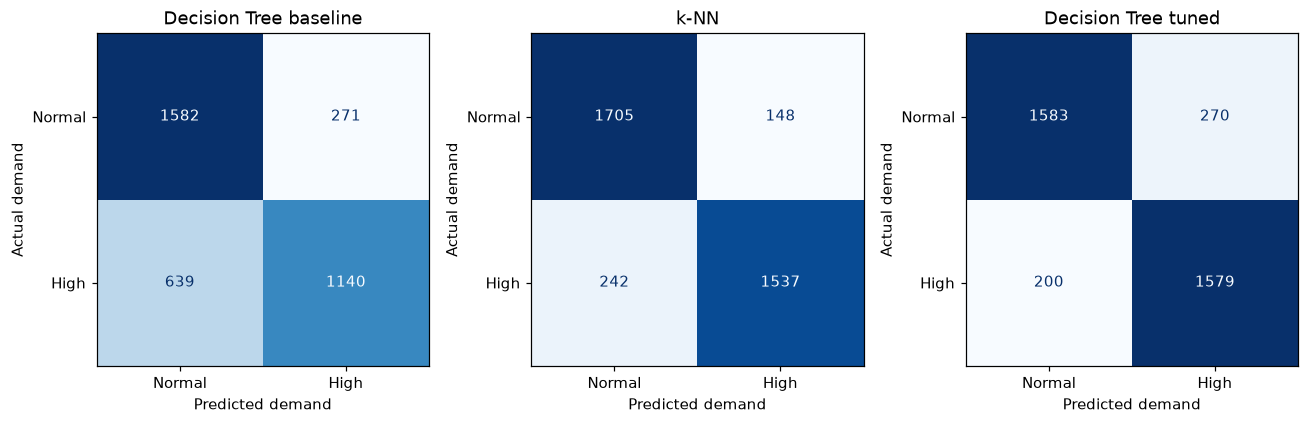

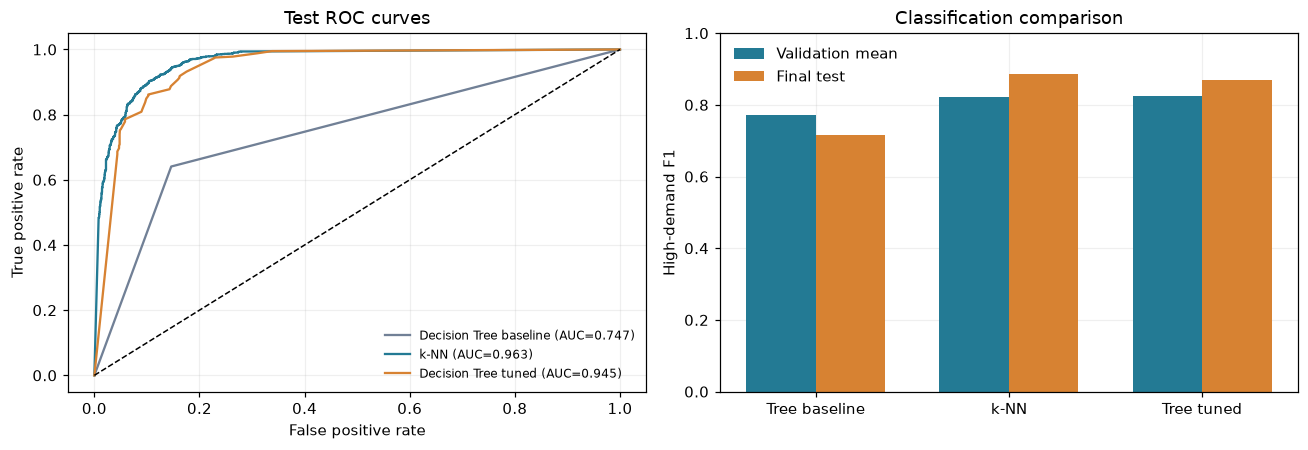

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for axis, (name, matrix) in zip(axes, confusion_matrices.items()):
    ConfusionMatrixDisplay(matrix, display_labels=['Normal', 'High']).plot(
        ax=axis, colorbar=False, cmap='Blues', values_format='d')
    axis.set_title(name)
    axis.set_xlabel('Predicted demand')
    axis.set_ylabel('Actual demand')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
colors = ['#718096', '#237a94', '#d78232']
for (name, probability), color in zip(probabilities.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, probability)
    auc_value = classification_results.loc[name, 'ROC-AUC']
    axes[0].plot(fpr, tpr, color=color, label=f'{name} (AUC={auc_value:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='black', linewidth=1)
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Test ROC curves')
axes[0].legend(fontsize=8, frameon=False, loc='lower right')
positions = np.arange(3)
axes[1].bar(positions - 0.18, classification_results['CV F1'], 0.36,
            color='#237a94', label='Validation mean')
axes[1].bar(positions + 0.18, classification_results['F1'], 0.36,
            color='#d78232', label='Final test')
axes[1].set(xticks=positions, xticklabels=['Tree baseline', 'k-NN', 'Tree tuned'],
            ylabel='High-demand F1', title='Classification comparison', ylim=(0, 1))
axes[1].legend(frameon=False)
for axis in axes:
    axis.grid(alpha=0.2)
    axis.set_axisbelow(True)
fig.tight_layout()
plt.show()

**Interpretation:** Grid search selected unrestricted depth, **10 samples per leaf**, and no
class reweighting. The leaf-size constraint reduces reliance on tiny leaves. Mean CV F1
improves from **0.7705 to 0.8256**, or **5.51 percentage points**.
Test F1 improves from **0.7147 to 0.8705**.

The tuned tree leads mean CV F1 by only **0.0036** over k-NN, so validation does not show a
large gap. The recommendation remains the tuned tree under the stated selection rule.
**k-NN has the best final test F1 (0.8874), accuracy (89.26%), and ROC-AUC (0.9629)**.
The tuned tree has higher recall (**88.76%** versus **86.40%**): it misses **200** high-demand
hours compared with **242** for k-NN, while k-NN gives fewer false warnings (**148** versus **270**).
The confusion matrices show this tradeoff. Different future periods may change the ranking.

## 5. K-Means clustering and cluster-count selection

K-Means groups similar hours by cyclic hour, normalized temperature, humidity, wind speed,
working-day status, and weather category. Numeric values are standardized and categories
are one-hot encoded. Rental counts and the high-demand label are excluded. Apparent
temperature is omitted here because it nearly duplicates temperature.

Preprocessing and K-Means are fitted on training hours. Cluster counts **2–6** are compared
using silhouette on the same reproducible 2,000-hour training sample. The highest sampled
silhouette selects k; scores nearer 1 indicate better separation under this distance measure
(Wu, 2024, Chapter 8). There are no known true cluster labels.

In [6]:
cluster_numeric = ['hour_sin_1', 'hour_cos_1', 'temperature_norm',
                   'humidity_norm', 'windspeed_norm']
cluster_categories = ['working_day', 'weather']
cluster_inputs = cluster_numeric + cluster_categories
assert not {'total_rentals', 'casual_rentals', 'registered_rentals', 'high_demand'} & set(cluster_inputs)
cluster_preprocess = ColumnTransformer([
    ('numeric', StandardScaler(), cluster_numeric),
    ('category', OneHotEncoder(categories=[[0, 1], [1, 2, 3, 4]],
                               handle_unknown='ignore', sparse_output=False), cluster_categories)
])
cluster_train = cluster_preprocess.fit_transform(train[cluster_inputs])
sample_idx = np.random.default_rng(42).choice(len(train), size=2000, replace=False)
cluster_models, cluster_rows = {}, []
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(cluster_train)
    cluster_models[k] = model
    cluster_rows.append({'k': k, 'Sample silhouette': silhouette_score(
        cluster_train[sample_idx], model.labels_[sample_idx]), 'Inertia': model.inertia_})
cluster_selection = pd.DataFrame(cluster_rows)
best_k = int(cluster_selection.loc[cluster_selection['Sample silhouette'].idxmax(), 'k'])
kmeans = cluster_models[best_k]
cluster_labels = kmeans.labels_
display(cluster_selection.round(4))
print('Selected cluster count:', best_k)

,k,Sample silhouette,Inertia
0,2,0.1946,"64,570.9468"
1,3,0.1762,"56,840.6279"
2,4,0.1652,"51,528.0854"
3,5,0.1480,"48,254.7400"
4,6,0.1518,"45,337.0052"


Selected cluster count: 2


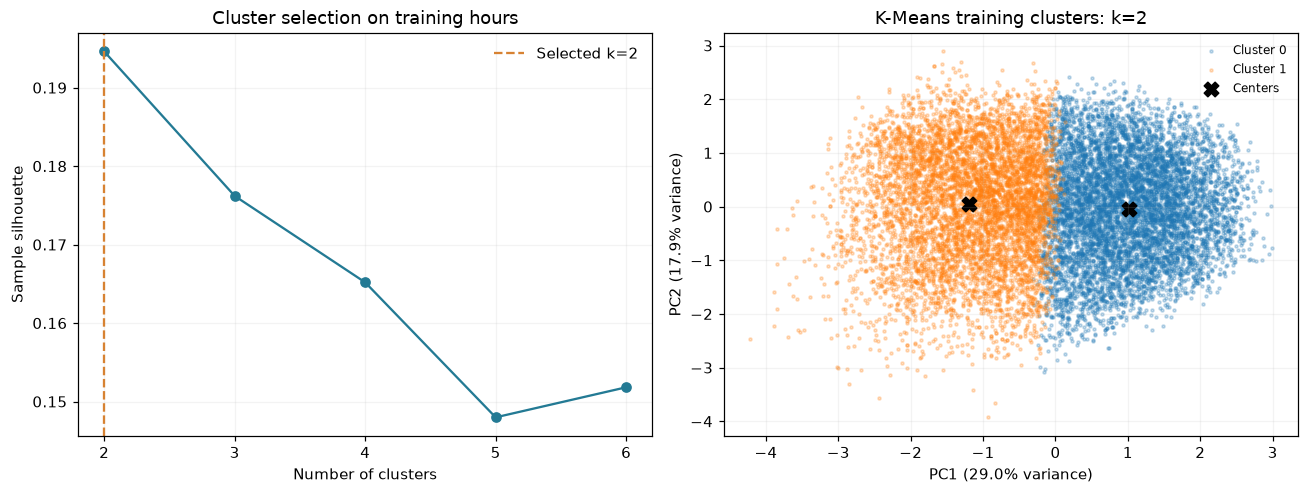

,Hours,Temperature,Humidity,Wind,Working_day_pct,Daytime_pct,Mean_rentals,High_demand_pct
cluster,,,,,,,,
0,7429,0.4500,0.7400,0.1500,68.1800,38.5100,98.6600,14.1700
1,6318,0.5500,0.4800,0.2500,68.7400,82.4500,261.3900,53.1000


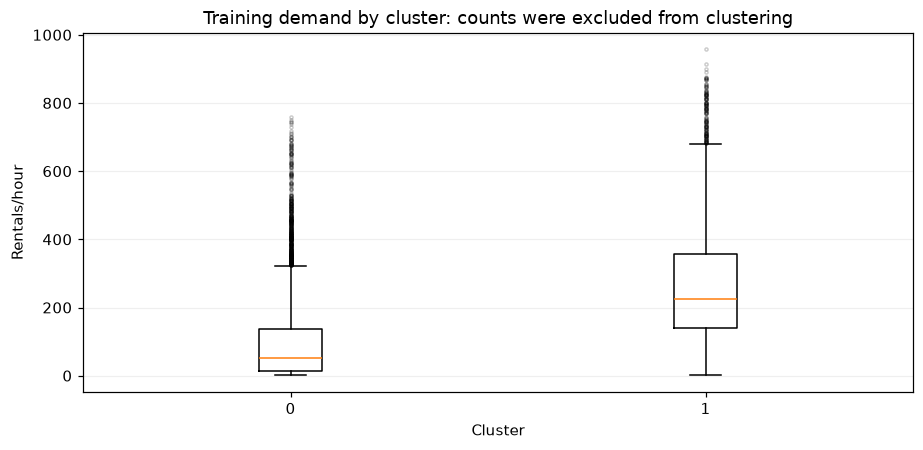

In [7]:
# PCA is only a two-dimensional view; K-Means used the full transformed feature space.
pca = PCA(n_components=2)
projected = pca.fit_transform(cluster_train)
centers = pca.transform(kmeans.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(cluster_selection['k'], cluster_selection['Sample silhouette'], 'o-', color='#237a94')
axes[0].axvline(best_k, linestyle='--', color='#d78232', label=f'Selected k={best_k}')
axes[0].set(xlabel='Number of clusters', ylabel='Sample silhouette',
            title='Cluster selection on training hours', xticks=list(range(2, 7)))
axes[0].legend(frameon=False)
palette = plt.get_cmap('tab10')
for group in range(best_k):
    mask = cluster_labels == group
    axes[1].scatter(projected[mask, 0], projected[mask, 1], s=4, alpha=0.25,
                    color=palette(group), label=f'Cluster {group}')
axes[1].scatter(centers[:, 0], centers[:, 1], marker='X', c='black', s=90, label='Centers')
axes[1].set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)',
            ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)',
            title=f'K-Means training clusters: k={best_k}')
axes[1].legend(fontsize=8, markerscale=1, frameon=False)
for axis in axes:
    axis.grid(alpha=0.15)
fig.tight_layout()
plt.show()

# Add rental outcomes only after clustering, for descriptive profiles.
profile_data = train.assign(cluster=cluster_labels,
                            daytime=train['hour'].between(6, 19).astype(int))
cluster_profiles = profile_data.groupby('cluster').agg(
    Hours=('total_rentals', 'size'), Temperature=('temperature_norm', 'mean'),
    Humidity=('humidity_norm', 'mean'), Wind=('windspeed_norm', 'mean'),
    Working_day_pct=('working_day', lambda x: 100 * x.mean()),
    Daytime_pct=('daytime', lambda x: 100 * x.mean()),
    Mean_rentals=('total_rentals', 'mean'),
    High_demand_pct=('high_demand', lambda x: 100 * x.mean()))
cluster_profiles.round(4).to_csv(OUTPUT / 'cluster_profiles.csv')
display(cluster_profiles.round(2))

fig, axis = plt.subplots(figsize=(8.5, 4.2))
boxes = [profile_data.loc[profile_data['cluster'] == group, 'total_rentals']
         for group in range(best_k)]
axis.boxplot(boxes, tick_labels=[str(i) for i in range(best_k)],
             flierprops={'markersize': 2, 'alpha': 0.2})
axis.set(xlabel='Cluster', ylabel='Rentals/hour',
          title='Training demand by cluster: counts were excluded from clustering')
axis.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

**Interpretation:** **k = 2** has the highest sampled silhouette among the tested counts,
**0.1946**. This is modest separation: the clusters summarize broad conditions rather
than sharply distinct types. The PCA view displays **46.9%** of transformed-feature variance,
so it cannot show all distances used by K-Means.

- **Cluster 0: Cooler, more humid hours.** 7,429 training hours; mean normalized temperature **0.448**, humidity **0.744**, and wind **0.148**. Daytime accounts for **38.5%** of the group. Average demand is **98.7 rentals/hour**, with **14.2%** classified as high demand.
- **Cluster 1: Warmer, less humid, mostly daytime hours.** 6,318 training hours; mean normalized temperature **0.553**, humidity **0.480**, and wind **0.248**. Daytime accounts for **82.4%** of the group. Average demand is **261.4 rentals/hour**, with **53.1%** classified as high demand.

Working-day rates are similar in the two groups, around 68%. Their profiles suggest that
time of day and weather account for more of this grouping. The boxplot shows higher demand
in Cluster 1, but there is substantial overlap. Demand differences are descriptions added
after clustering, not inputs or proof of a causal effect.

## 6. Association rule mining with FP-Growth

Each hour is a transaction of conditions, not a shopping basket. Transactions contain:

- Time period: night 00–05, morning 06–09, midday 10–15, evening 16–19, late 20–23.
- Working or non-working day, and clear, mist, or rain/snow weather.
- Cool, mild, or warm temperature, based on training-set tertiles.
- High or normal demand, using the same fixed classification threshold.

FP-Growth mines training hours with **minimum support 3%** and itemsets of at most three
items. Rules must have **confidence ≥70%**, **lift ≥1.2**, and only `demand=high` on the right.
This retains interpretable conditions leading to high demand and removes calendar rules that
only restate definitions. At most two conditions appear on the left.

**Support** is the fraction of hours containing both the conditions and high demand.
**Confidence** is the fraction of matching hours with high demand. **Lift** compares that
confidence with the overall high-demand rate. Lift above 1 indicates a positive association,
not proof of causation or statistical significance (Wu, 2024, Chapter 9).

In [8]:
temperature_edges = train['temperature_norm'].quantile([1 / 3, 2 / 3]).to_numpy()

def transactions(frame):
    # All labels and temperature boundaries are fixed before testing the rules.
    conditions = pd.DataFrame(index=frame.index)
    conditions['period'] = pd.cut(frame['hour'], [-1, 5, 9, 15, 19, 23],
                                   labels=['night', 'morning', 'midday', 'evening', 'late'])
    conditions['day'] = np.where(frame['working_day'] == 1, 'working', 'nonworking')
    conditions['weather'] = frame['weather'].map({1: 'clear', 2: 'mist', 3: 'rain_snow', 4: 'rain_snow'})
    conditions['temperature'] = pd.cut(frame['temperature_norm'],
        [-np.inf, *temperature_edges, np.inf], labels=['cool', 'mild', 'warm'])
    conditions['demand'] = np.where(frame['high_demand'] == 1, 'high', 'normal')
    assert not conditions.isna().any().any()
    return pd.get_dummies(conditions, prefix_sep='=').astype(bool)

arm_train = transactions(train)
arm_test = transactions(test).reindex(columns=arm_train.columns, fill_value=False)
itemsets = fpgrowth(arm_train, min_support=0.03, max_len=3, use_colnames=True)
rules = association_rules(itemsets, num_itemsets=len(arm_train),
                           metric='confidence', min_threshold=0.70)
rules = rules[(rules['consequents'] == frozenset({'demand=high'})) & (rules['lift'] >= 1.2)]
rules = rules[rules['antecedents'].apply(lambda items: not any(x.startswith('demand=') for x in items))]
rules = rules.sort_values(['lift', 'support'], ascending=False).reset_index(drop=True)
assert len(rules) > 0

# Check the fixed training rules on later hours without selecting rules by test results.
rule_rows = []
test_high_rate = arm_test['demand=high'].mean()
for _, rule in rules.iterrows():
    antecedent = sorted(rule['antecedents'])
    matches = arm_test[antecedent].all(axis=1)
    high_matches = matches & arm_test['demand=high']
    confidence = high_matches.sum() / matches.sum() if matches.any() else np.nan
    rule_rows.append({'Conditions': ' & '.join(antecedent), 'Outcome': 'demand=high',
        'Train count': int(round(rule['support'] * len(arm_train))),
        'Train support': rule['support'], 'Train confidence': rule['confidence'],
        'Train lift': rule['lift'], 'Test matches': int(matches.sum()),
        'Test support': high_matches.mean(), 'Test confidence': confidence,
        'Test lift': confidence / test_high_rate})
rule_results = pd.DataFrame(rule_rows)
rule_results.round(4).to_csv(OUTPUT / 'association_rules.csv', index=False)
print(f'Temperature cut points (normalized units): {temperature_edges}')
print(f'Frequent itemsets: {len(itemsets)}; qualifying high-demand rules: {len(rule_results)}')
print(f'High-demand base rates: training={y_train.mean():.1%}, test={y_test.mean():.1%}')
display(rule_results.head(6).round(4))

Temperature cut points (normalized units): [0.38 0.62]
Frequent itemsets: 208; qualifying high-demand rules: 6
High-demand base rates: training=32.1%, test=49.0%


,Conditions,Outcome,Train count,Train support,Train confidence,Train lift,Test matches,Test support,Test confidence,Test lift
0,period=evening & temperature=warm,demand=high,887,0.0645,0.9652,3.0101,221,0.0603,0.9910,2.0231
1,period=evening & temperature=mild,demand=high,626,0.0455,0.7975,2.4870,219,0.0556,0.9224,1.8831
2,period=evening & weather=clear,demand=high,1290,0.0938,0.7900,2.4636,393,0.0999,0.9237,1.8857
3,day=working & period=evening,demand=high,1234,0.0898,0.7800,2.4326,412,0.1068,0.9417,1.9227
4,period=evening,demand=high,1685,0.1226,0.7301,2.2768,608,0.1476,0.8816,1.7998
5,day=nonworking & period=midday,demand=high,783,0.0570,0.7170,2.2362,294,0.0691,0.8537,1.7430


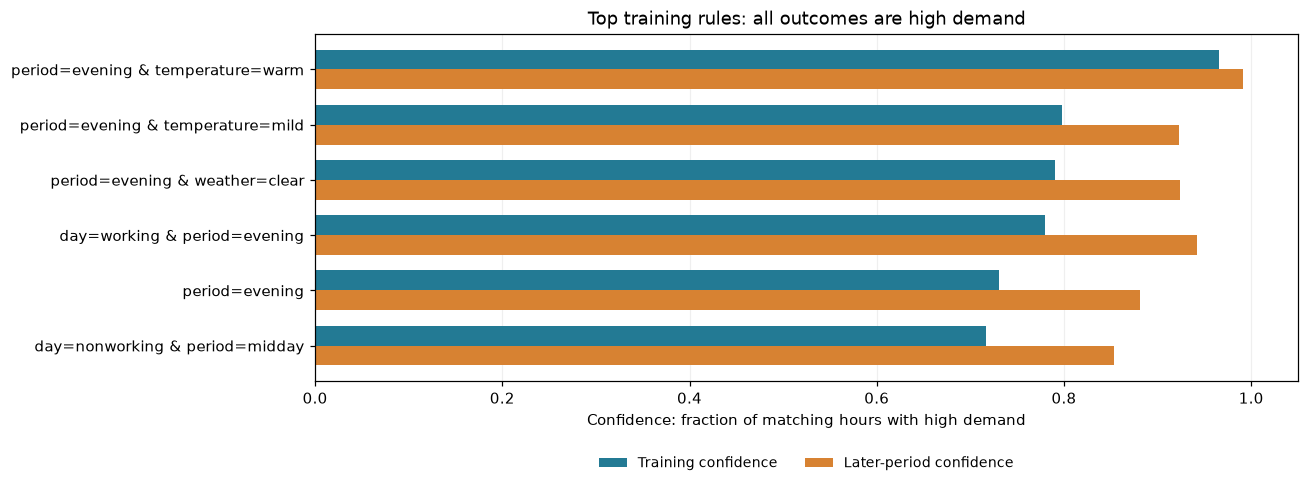

In [9]:
top_rules = rule_results.head(6)
positions = np.arange(len(top_rules))
fig, axis = plt.subplots(figsize=(12, 4.6))
axis.barh(positions - 0.18, top_rules['Train confidence'], 0.36,
           color='#237a94', label='Training confidence')
axis.barh(positions + 0.18, top_rules['Test confidence'], 0.36,
           color='#d78232', label='Later-period confidence')
axis.set(yticks=positions, yticklabels=top_rules['Conditions'],
          xlabel='Confidence: fraction of matching hours with high demand',
          title='Top training rules: all outcomes are high demand', xlim=(0, 1.05))
axis.invert_yaxis()
axis.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18),
             ncol=2, fontsize=9)
axis.grid(axis='x', alpha=0.2)
axis.set_axisbelow(True)
fig.tight_layout()
plt.show()

**Interpretation:** FP-Growth finds **6 qualifying high-demand rules** from
**208 frequent itemsets**. The strongest training rule is
**warm evenings → high demand**, where evening is 16:00–19:59 and warm means normalized
temperature above **0.62**.

- Support **6.45%**: **887 training hours** satisfy both conditions and high demand.
- Confidence **96.52%**: almost all matching warm evening hours have high demand.
- Lift **3.01**: this confidence is about three times the overall training high-demand rate.
- Later-period confidence **99.10%**, based on **221 matching test hours**.

Another useful rule is **non-working midday → high demand**, with training confidence
**71.70%** and lift **2.24**. These patterns support reviewing bicycle
availability for warm evenings and non-working midday periods. The overall high-demand rate
also rises from **32.1%** in training to **49.0%** in testing, so confidence and lift
must be interpreted against each period's base rate. Consecutive hours are related observations;
the later-period check is descriptive evidence, not an independent causal test.

## 7. Findings, practical applications, and challenges

- **Classification:** Decision Tree and k-NN meet the two-model requirement. k-NN has
  the strongest final test F1 (**0.8874**); the tuned tree leads the stated validation criterion
  (**CV F1 0.8256**) and detects more high-demand hours.
- **Tuning:** A minimum of 10 observations per leaf improves validation and test F1 over
  the default tree. Parameter selection uses training folds only.
- **Clustering:** Two broad groups separate cooler, more humid hours from warmer, mainly
  daytime hours. Their average demand differs, which can inform condition-based planning.
- **Pattern mining:** Six rules highlight high-demand conditions. Warm evenings and
  non-working midday periods provide specific windows to examine for extra bicycles or staff.
  Rules describe associations rather than guaranteed forecasts.

| Challenge | How it was addressed |
|---|---|
| Defining high demand without later outcomes changing its meaning. | Fixed the threshold using only the first training window. |
| Class proportions and demand change over time. | Reported class proportions, high-demand F1, recall, ROC-AUC, and later-period performance. |
| Distance methods depend on feature scale. | Standardized numeric inputs for k-NN and K-Means; fitted transformations on training data. |
| Rental counts would reveal the class or dominate clusters. | Excluded count columns from classifiers and clustering inputs. |
| Tuning can favor noisy trees. | Compared depth, leaf size, and class weighting using five calendar folds. |
| Association mining can produce trivial rules. | Restricted outcomes to high demand and required support, confidence, and lift thresholds. |

These findings describe recorded conditions in one historical system. Recorded weather is
available during the hour; advance prediction would require weather forecasts available at
prediction time. Clusters are exploratory groups, and association rules do not establish causes.
Deliverable 1 already explored the full dataset, so the test is a later-period check rather
than a completely unseen research dataset. Deliverable 4 can combine these findings with
the earlier cleaning, EDA, and regression results.

## References

Fanaee-T, H. (2013). *Bike sharing* [Data set]. UCI Machine Learning Repository.
https://doi.org/10.24432/C5W894  
License: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Cleaned names and derived
calendar features were prepared in this project.

Scikit-learn developers. (n.d.). *GridSearchCV*.
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

Scikit-learn developers. (n.d.). *KMeans*.
https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

Raschka, S. (n.d.). *Association rules*. Mlxtend.
https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/

Wu, D. (2024). *Data mining with Python: Theory, application, and case studies*. CRC Press.